# 03 — VaR à 99 %, backtesting et Expected Shortfall

Quatre méthodes, recalculées **chaque jour avec les seules données de la veille** :

| Méthode | Principe |
|---|---|
| Historique, tout l'historique | 1er centile de tous les P&L passés |
| Historique glissante, 250 jours | 1er centile des 250 derniers P&L |
| EWMA normale (RiskMetrics, λ = 0,94) | 2,33 × σ_EWMA |
| FHS (simulation historique filtrée) | 1er centile historique de r / σ_EWMA, × σ_EWMA du jour |

In [1]:
import sys
from pathlib import Path

# Racine du projet (le notebook est dans notebooks/)
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RACINE))
DATA, FIGURES = RACINE / "data", RACINE / "figures"
FIGURES.mkdir(exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.var_tools import (
    rendements_portefeuille, var_historique, sigma_ewma, var_ewma_normale,
    rendements_standardises, var_fhs, es_fhs, var_es_historiques, var_es_normales,
    intervalle_binomial, tableau_backtest,
)

MONTANT, ALPHA, LAMBDA = 100_000, 0.01, 0.94
POIDS = pd.Series({"TTE.PA": 1/3, "SXR8.DE": 1/3, "EUNH.DE": 1/3})

prix = pd.read_csv(DATA / "prix.csv", index_col=0, parse_dates=True)
rend_pf = rendements_portefeuille(prix, POIDS)
pnl = MONTANT * rend_pf

## 1. VaR statique : un piège in-sample

Calculée sur les 10 ans puis comparée à ces mêmes 10 ans, la VaR à 99 % est dépassée 1 % du temps
**par construction** : ce chiffre ne prouve rien. Elle sert seulement à comparer avec la loi normale.

In [3]:
for a in [0.01, 0.05]:
    var_h, _, _ = var_es_historiques(pnl, a)
    var_n, _ = var_es_normales(pnl.std(), a)
    print(f"VaR {1-a:.0%} : historique {var_h:6,.0f} € | normale {var_n:6,.0f} € | écart {var_h/var_n - 1:+.0%}")

var99_h, _, _ = var_es_historiques(pnl, ALPHA)
print("Dépassements in-sample :", (pnl < -var99_h).sum(), "sur", len(pnl), "jours")

VaR 99% : historique  2,167 € | normale  1,795 € | écart +21%
VaR 95% : historique  1,071 € | normale  1,269 € | écart -16%
Dépassements in-sample : 28 sur 2751 jours


## 2. Les quatre VaR, jour par jour

In [4]:
sigma = sigma_ewma(rend_pf, LAMBDA)
z = rendements_standardises(rend_pf, sigma)

print(f"Kurtosis : brute {rend_pf.kurt():.1f} → standardisée {z.kurt():.1f}")
print(f"1er centile des rendements standardisés : {z.quantile(ALPHA):.2f} (loi normale : -2,33)")

df = pd.DataFrame({
    "pnl": pnl,
    "var_250": var_historique(pnl, ALPHA, fenetre=250),
    "var_exp": var_historique(pnl, ALPHA, fenetre=None),
}).dropna()
df["var_ewma"] = var_ewma_normale(sigma, MONTANT, ALPHA)
df["var_fhs"] = var_fhs(z, sigma, MONTANT, ALPHA)
df["es_fhs"] = es_fhs(z, sigma, MONTANT, ALPHA)

Kurtosis : brute 16.1 → standardisée 2.7
1er centile des rendements standardisés : -2.95 (loi normale : -2,33)


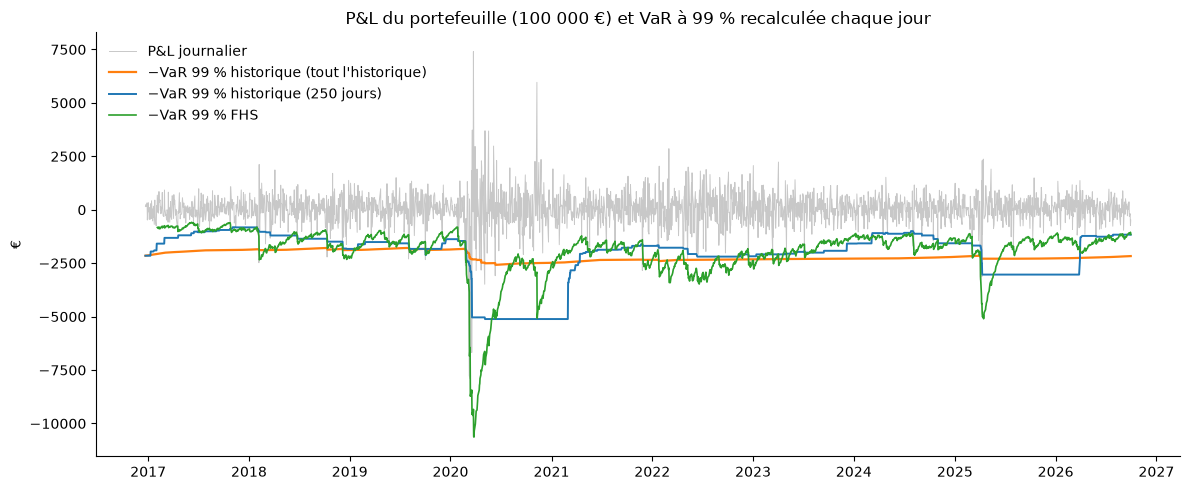

In [5]:
NOMS = {"var_250": "Historique 250 j", "var_exp": "Historique (tout)",
        "var_ewma": "EWMA normale", "var_fhs": "FHS"}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df["pnl"], color="#c8c8c8", linewidth=0.7, label="P&L journalier")
ax.plot(df.index, -df["var_exp"], color="C1", linewidth=1.6, label="−VaR 99 % historique (tout l'historique)")
ax.plot(df.index, -df["var_250"], color="C0", linewidth=1.4, label="−VaR 99 % historique (250 jours)")
ax.plot(df.index, -df["var_fhs"], color="C2", linewidth=1.2, label="−VaR 99 % FHS")
ax.set_ylabel("€")
ax.set_title("P&L du portefeuille (100 000 €) et VaR à 99 % recalculée chaque jour")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "var_backtest.png", dpi=150)
plt.show()

## 3. Dépassements par année

Un modèle parfait en produit environ 2,6 par an (1 % de ~256 jours), **et de façon dispersée**.

In [6]:
par_an = pd.DataFrame({NOMS[c]: (df["pnl"] < -df[c]) for c in NOMS}).groupby(df.index.year).sum()
par_an

,Historique 250 j,Historique (tout),EWMA normale,FHS
Date,,,,
2016,0,0,0,0
2017,1,0,2,4
2018,8,3,8,7
2019,2,2,8,4
2020,9,13,10,6
2021,1,1,6,5
2022,5,1,5,2
2023,1,0,3,2
2024,7,0,8,2


## 4. Backtesting formel

Période commune aux quatre modèles. **Kupiec** teste le nombre de dépassements, **Christoffersen**
teste leur indépendance (un modèle parfait a 1 % de chances de dépassement, même le lendemain d'un
dépassement), la **couverture conditionnelle** combine les deux (χ² à 2 degrés de liberté).

In [7]:
bt = df.dropna(subset=list(NOMS))
T = len(bt)
bas, haut = intervalle_binomial(T, ALPHA)
print(f"{T} jours testés | attendus : {T*ALPHA:.1f} | intervalle à 95 % : [{bas:.0f} ; {haut:.0f}]")

resultats = tableau_backtest(bt["pnl"], bt[list(NOMS)], ALPHA).rename(index=NOMS)
resultats.style.format({
    "dépassements": "{:.0f}", "taux": "{:.2%}", "LR_Kupiec": "{:.2f}", "p_Kupiec": "{:.3f}",
    "π01": "{:.2%}", "π11": "{:.2%}", "LR_indép": "{:.2f}", "p_indép": "{:.3f}",
    "p_couverture_cond": "{:.3f}",
})

2471 jours testés | attendus : 24.7 | intervalle à 95 % : [16 ; 35]


,dépassements,taux,LR_Kupiec,p_Kupiec,π01,π11,LR_indép,p_indép,p_couverture_cond
Historique 250 j,40,1.62%,8.05,0.005,1.44%,12.50%,12.74,0.000,0.000
Historique (tout),24,0.97%,0.02,0.885,0.82%,16.67%,16.47,0.000,0.000
EWMA normale,59,2.39%,34.60,0.000,2.16%,11.86%,12.39,0.000,0.000
FHS,36,1.46%,4.57,0.033,1.44%,2.78%,0.35,0.553,0.085


## 5. Expected Shortfall

L'ES est la perte moyenne au-delà de la VaR. Depuis la réforme FRTB, le capital pour risque de marché
repose sur l'ES à 97,5 %, qui vaut presque exactement la VaR à 99 % pour une loi normale.

In [8]:
var99_h, es99_h, n_queue = var_es_historiques(pnl, 0.01)
var99_n, es99_n = var_es_normales(pnl.std(), 0.01)
_, es975_h, _ = var_es_historiques(pnl, 0.025)
_, es975_n = var_es_normales(pnl.std(), 0.025)

print(f"Jours dans la queue à 99 % : {n_queue}")
print(f"Historique : VaR 99 % {var99_h:,.0f} € | ES 99 % {es99_h:,.0f} € | ES/VaR {es99_h/var99_h:.2f}")
print(f"Normale    : VaR 99 % {var99_n:,.0f} € | ES 99 % {es99_n:,.0f} € | ES/VaR {es99_n/var99_n:.2f}")
print(f"Sous-estimation par la loi normale : VaR {var99_n/var99_h - 1:+.0%} | ES {es99_n/es99_h - 1:+.0%}\n")
print(f"Loi normale : VaR 99 % {var99_n:,.0f} € ≈ ES 97,5 % {es975_n:,.0f} €")
print(f"Portefeuille : ES 97,5 % {es975_h:,.0f} € → {es975_h/var99_h - 1:+.0%} de capital par rapport à la VaR 99 %")

Jours dans la queue à 99 % : 28
Historique : VaR 99 % 2,167 € | ES 99 % 3,231 € | ES/VaR 1.49
Normale    : VaR 99 % 1,795 € | ES 99 % 2,056 € | ES/VaR 1.15
Sous-estimation par la loi normale : VaR -17% | ES -36%

Loi normale : VaR 99 % 1,795 € ≈ ES 97,5 % 1,804 €
Portefeuille : ES 97,5 % 2,399 € → +11% de capital par rapport à la VaR 99 %


### ES de la FHS, testée jour par jour

Les jours où la VaR FHS est dépassée, on compare la perte réelle à l'ES prévue le matin même.
Un rapport moyen de 1 signifie que l'ES estime correctement la gravité des dépassements.

In [9]:
jours = df[df["pnl"] < -df["var_fhs"]]
ratio = -jours["pnl"] / jours["es_fhs"]
print(f"{len(jours)} jours de dépassement | perte réelle / ES prévue : {ratio.mean():.2f} en moyenne")
jours[["pnl", "var_fhs", "es_fhs"]].round(0).assign(ratio=ratio.round(2))

36 jours de dépassement | perte réelle / ES prévue : 1.01 en moyenne


,pnl,var_fhs,es_fhs,ratio
Date,,,,
2017-04-18,-920.0,766.0,1085.0,0.85
2017-06-14,-631.0,612.0,748.0,0.84
2017-06-29,-1034.0,665.0,774.0,1.34
2017-10-25,-657.0,613.0,754.0,0.87
2018-01-30,-1029.0,816.0,975.0,1.06
2018-02-02,-1078.0,930.0,1142.0,0.94
2018-02-06,-2476.0,1235.0,1472.0,1.68
2018-06-25,-1386.0,1213.0,1583.0,0.88
2018-08-15,-1142.0,1134.0,1444.0,0.79
